In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn


[notice] A new release of pip is available: 23.2.1 -> 25.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from sklearn.feature_selection import VarianceThreshold
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
import gc
import warnings
warnings.filterwarnings('ignore')

gc.enable()

In [3]:
# Let's do some feature engineering

bureau_balance = pd.read_csv('./data/home-credit-default-risk/bureau_balance.csv')
print(bureau_balance.shape)

print('transform to dummies')
bureau_balance = pd.concat([bureau_balance, pd.get_dummies(bureau_balance.STATUS, prefix="bureau_balance_status")], axis=1).drop('STATUS', axis=1)

bureau_balance.head()

(27299925, 3)
transform to dummies


,SK_ID_BUREAU,MONTHS_BALANCE,bureau_balance_status_0,bureau_balance_status_1,bureau_balance_status_2,bureau_balance_status_3,bureau_balance_status_4,bureau_balance_status_5,bureau_balance_status_C,bureau_balance_status_X
0,5715448,0,False,False,False,False,False,False,True,False
1,5715448,-1,False,False,False,False,False,False,True,False
2,5715448,-2,False,False,False,False,False,False,True,False
3,5715448,-3,False,False,False,False,False,False,True,False
4,5715448,-4,False,False,False,False,False,False,True,False


In [4]:
bureau_counts = bureau_balance[['SK_ID_BUREAU', 'MONTHS_BALANCE']].groupby('SK_ID_BUREAU').count()
bureau_balance['bureau_count'] = bureau_balance['SK_ID_BUREAU'].map(bureau_counts['MONTHS_BALANCE'])

# bureau_balance.head()

average_bureau_balance = bureau_balance.groupby('SK_ID_BUREAU').mean()
average_bureau_balance.columns = ['average_bur_' + f_ for f_ in average_bureau_balance.columns]

del bureau_balance
gc.collect()

17

In [5]:
average_bureau_balance.head(100)

,average_bur_MONTHS_BALANCE,average_bur_bureau_balance_status_0,average_bur_bureau_balance_status_1,average_bur_bureau_balance_status_2,average_bur_bureau_balance_status_3,average_bur_bureau_balance_status_4,average_bur_bureau_balance_status_5,average_bur_bureau_balance_status_C,average_bur_bureau_balance_status_X,average_bur_bureau_count
SK_ID_BUREAU,,,,,,,,,,
5001709,-48.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.886598,0.113402,97.0
5001710,-41.0,0.060241,0.0,0.0,0.0,0.0,0.0,0.578313,0.361446,83.0
5001711,-1.5,0.750000,0.0,0.0,0.0,0.0,0.0,0.000000,0.250000,4.0
5001712,-9.0,0.526316,0.0,0.0,0.0,0.0,0.0,0.473684,0.000000,19.0
5001713,-10.5,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,1.000000,22.0
...,...,...,...,...,...,...,...,...,...,...
5001804,-4.5,0.600000,0.0,0.0,0.0,0.0,0.0,0.400000,0.000000,10.0
5001805,-11.0,0.173913,0.0,0.0,0.0,0.0,0.0,0.826087,0.000000,23.0
5001806,-17.0,0.342857,0.0,0.0,0.0,0.0,0.0,0.657143,0.000000,35.0


In [6]:
print('Read Bureau')
bureau = pd.read_csv('./data/home-credit-default-risk/bureau.csv')

Read Bureau


In [7]:
categorical_coulmns_bureau = bureau.select_dtypes(include='object').columns

print('Creating dummies for categorical variables : One hot encoding')
bureau_credit_active_dum = pd.get_dummies(bureau.CREDIT_ACTIVE, prefix='ca_')
bureau_credit_currency_dum = pd.get_dummies(bureau.CREDIT_CURRENCY, prefix='cu_')
bureau_credit_type_dum = pd.get_dummies(bureau.CREDIT_TYPE, prefix='ty_')

# Drop the categorical coulmns from the original dataframe
bureau.drop(categorical_coulmns_bureau, axis=1, inplace=True)

bureau_full = pd.concat([bureau, bureau_credit_active_dum, bureau_credit_currency_dum, bureau_credit_type_dum], axis=1)

Creating dummies for categorical variables : One hot encoding


In [8]:
bureau_full.head()

,SK_ID_CURR,SK_ID_BUREAU,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,...,ty__Interbank credit,ty__Loan for business development,ty__Loan for purchase of shares (margin lending),ty__Loan for the purchase of equipment,ty__Loan for working capital replenishment,ty__Microloan,ty__Mobile operator loan,ty__Mortgage,ty__Real estate loan,ty__Unknown type of loan
0,215354,5714462,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,...,False,False,False,False,False,False,False,False,False,False
1,215354,5714463,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,...,False,False,False,False,False,False,False,False,False,False
2,215354,5714464,-203,0,528.0,NaN,NaN,0,464323.5,NaN,...,False,False,False,False,False,False,False,False,False,False
3,215354,5714465,-203,0,NaN,NaN,NaN,0,90000.0,NaN,...,False,False,False,False,False,False,False,False,False,False
4,215354,5714466,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,...,False,False,False,False,False,False,False,False,False,False


In [9]:
del bureau_credit_active_dum, bureau_credit_currency_dum, bureau_credit_type_dum
gc.collect()


10

In [10]:
bureau_full = bureau_full.merge(right=average_bureau_balance.reset_index(), how='left', on='SK_ID_BUREAU', suffixes=('', '_bur_bal'))
bureau_full.head(1000)

,SK_ID_CURR,SK_ID_BUREAU,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,...,average_bur_MONTHS_BALANCE,average_bur_bureau_balance_status_0,average_bur_bureau_balance_status_1,average_bur_bureau_balance_status_2,average_bur_bureau_balance_status_3,average_bur_bureau_balance_status_4,average_bur_bureau_balance_status_5,average_bur_bureau_balance_status_C,average_bur_bureau_balance_status_X,average_bur_bureau_count
0,215354,5714462,-497,0,-153.0,-153.0,NaN,0,91323.000,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,215354,5714463,-208,0,1075.0,NaN,NaN,0,225000.000,171342.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,215354,5714464,-203,0,528.0,NaN,NaN,0,464323.500,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,215354,5714465,-203,0,NaN,NaN,NaN,0,90000.000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,215354,5714466,-629,0,1197.0,NaN,77674.5,0,2700000.000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,394070,5715712,-831,0,-708.0,-708.0,0.0,0,24963.840,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
996,394070,5715713,-801,0,-678.0,-676.0,0.0,0,41331.735,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
997,285342,5715714,-110,0,468.0,-36.0,NaN,0,188700.525,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
998,285342,5715715,-414,0,10464.0,NaN,0.0,0,324000.000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# # The below code to group by bureau rows by SK_ID_CURR is throwing error due to categorical coulmns, lets convert them to numerical
# 
# categorical_coulmns_bureau = bureau_full.select_dtypes(include='object').columns
# # categorical_coulmns_bureau # ['CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'CREDIT_TYPE']
# 
# for column in categorical_coulmns_bureau:
#     print(column)
#     print(bureau_full[column].unique())
#     
# for column in categorical_coulmns_bureau:
#     bureau_full[column] = bureau_full[column].astype('category').cat.codes


In [12]:
# bureau_full.head(100)

In [13]:
nb_bureau_per_curr = bureau_full[['SK_ID_CURR', 'SK_ID_BUREAU']].groupby('SK_ID_CURR').count()
bureau_full['SK_ID_BUREAU'] = bureau_full['SK_ID_CURR'].map(nb_bureau_per_curr['SK_ID_BUREAU'])


In [14]:
average_bureau = bureau_full.groupby("SK_ID_CURR").mean()
# print(average_bureau.head())

In [15]:
del bureau, bureau_full
gc.collect()

10

In [16]:
previous_application = pd.read_csv('./data/home-credit-default-risk/previous_application.csv')

In [17]:
prev_app_categorical_features = [f_ for f_ in previous_application.columns if previous_application[f_].dtype == 'object']
# bureau_full.select_dtypes(include='object').columns

previous_application_dummies = pd.DataFrame()
for f_ in prev_app_categorical_features:
    previous_application_dummies = pd.concat([previous_application_dummies, pd.get_dummies(previous_application[f_], prefix=f_).astype(np.uint8)], axis=1)
    
previous_application.drop(prev_app_categorical_features, axis=1, inplace=True)
previous_application = pd.concat([previous_application, previous_application_dummies], axis=1)

In [18]:
del previous_application_dummies
gc.collect()

0

In [19]:
print('Counting the number of previous applications')
nb_prev_per_curr = previous_application[['SK_ID_CURR', 'SK_ID_PREV']].groupby('SK_ID_CURR').count()
previous_application['SK_ID_PREV'] = previous_application['SK_ID_CURR'].map(nb_prev_per_curr['SK_ID_PREV'])

Counting the number of previous applications


In [20]:
print('Averaging previous application')
average_previous_application = previous_application.groupby('SK_ID_CURR').mean()
average_previous_application.head()

Averaging previous application


,SK_ID_PREV,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,HOUR_APPR_PROCESS_START,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,...,PRODUCT_COMBINATION_Cash X-Sell: low,PRODUCT_COMBINATION_Cash X-Sell: middle,PRODUCT_COMBINATION_POS household with interest,PRODUCT_COMBINATION_POS household without interest,PRODUCT_COMBINATION_POS industry with interest,PRODUCT_COMBINATION_POS industry without interest,PRODUCT_COMBINATION_POS mobile with interest,PRODUCT_COMBINATION_POS mobile without interest,PRODUCT_COMBINATION_POS other with interest,PRODUCT_COMBINATION_POS others without interest
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100001,1.0,3951.000,24835.50,23787.00,2520.0,24835.5,13.000000,1.0,0.104326,NaN,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,1.0,0.0,0.0,0.0
100002,1.0,9251.775,179055.00,179055.00,0.0,179055.0,9.000000,1.0,0.000000,NaN,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,1.0,0.0
100003,3.0,56553.990,435436.50,484191.00,3442.5,435436.5,14.666667,1.0,0.050030,NaN,...,0.333333,0.0,0.333333,0.0,0.333333,0.0,0.0,0.0,0.0,0.0
100004,1.0,5357.250,24282.00,20106.00,4860.0,24282.0,5.000000,1.0,0.212008,NaN,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,1.0,0.0,0.0
100005,2.0,4813.200,22308.75,20076.75,4464.0,44617.5,10.500000,1.0,0.108964,NaN,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.5,0.0,0.0,0.0


In [21]:
del previous_application
gc.collect()

10

In [22]:
print('Reading POS CASH Balance')
pos_cash_balance = pd.read_csv('./data/home-credit-default-risk/pos_cash_balance.csv')


Reading POS CASH Balance


In [23]:
print('Convert the categorical into one hot encoded')
pos_cash_balance_categorical_features = [f_ for f_ in pos_cash_balance.columns if pos_cash_balance[f_].dtype == 'object']
pos_cash_balance_categorical_features

Convert the categorical into one hot encoded


['NAME_CONTRACT_STATUS']

In [24]:
pos_cash_balance = pd.concat([pos_cash_balance, pd.get_dummies(pos_cash_balance['NAME_CONTRACT_STATUS'])], axis=1)
pos_cash_balance.drop(pos_cash_balance_categorical_features, axis=1, inplace=True)

In [25]:
print('Computing nb of prevs per curr')
nb_prevs = pos_cash_balance[['SK_ID_CURR', 'SK_ID_PREV']].groupby('SK_ID_CURR').count()
pos_cash_balance['SK_ID_PREV'] = pos_cash_balance['SK_ID_CURR'].map(nb_prevs['SK_ID_PREV'])

Computing nb of prevs per curr


In [26]:
print('calculating averages of pos_cash_balance')
average_pos_cash_balance = pos_cash_balance.groupby('SK_ID_CURR').mean()

calculating averages of pos_cash_balance


In [27]:
del pos_cash_balance, nb_prevs
gc.collect()

10

In [28]:
print('Reading CC balance')
cc_bal = pd.read_csv('./data/home-credit-default-risk/credit_card_balance.csv')

print('Go to dummies')
cc_bal = pd.concat([cc_bal, pd.get_dummies(cc_bal['NAME_CONTRACT_STATUS'], prefix='cc_bal_status_')], axis=1)
cc_bal.drop(['NAME_CONTRACT_STATUS'], axis=1, inplace=True)

nb_prevs = cc_bal[['SK_ID_CURR', 'SK_ID_PREV']].groupby('SK_ID_CURR').count()
cc_bal['SK_ID_PREV'] = cc_bal['SK_ID_CURR'].map(nb_prevs['SK_ID_PREV'])

print('Compute average')
avg_cc_bal = cc_bal.groupby('SK_ID_CURR').mean()
avg_cc_bal.columns = ['cc_bal_' + f_ for f_ in avg_cc_bal.columns]

del cc_bal, nb_prevs
gc.collect()

Reading CC balance
Go to dummies
Compute average


0

In [29]:
print('Reading Installments')
inst = pd.read_csv('./data/home-credit-default-risk/installments_payments.csv')

nb_prevs = inst[['SK_ID_CURR', 'SK_ID_PREV']].groupby('SK_ID_CURR').count()
inst['SK_ID_PREV'] = inst['SK_ID_CURR'].map(nb_prevs['SK_ID_PREV'])

avg_inst = inst.groupby('SK_ID_CURR').mean()
avg_inst.columns = ['inst_' + f_ for f_ in avg_inst.columns]

Reading Installments


In [30]:
print("Let's merge all the data now in the training set.")
train_data = pd.read_csv('./data/home-credit-default-risk/application_train.csv')
test_data = pd.read_csv('./data/home-credit-default-risk/application_test.csv')

print('Shapes : ', train_data.shape, test_data.shape)

y = train_data['TARGET']
del train_data['TARGET']

Let's merge all the data now in the training set.
Shapes :  (307511, 122) (48744, 121)


In [31]:
categorical_feats = [
    f for f in train_data.columns if train_data[f].dtype == 'object'
]
categorical_feats
for f_ in categorical_feats:
    train_data[f_], indexer = pd.factorize(train_data[f_])
    test_data[f_] = indexer.get_indexer(test_data[f_])

In [32]:
train_data = train_data.merge(right = average_bureau.reset_index(), how='left', on="SK_ID_CURR")
test_data = test_data.merge(right = average_bureau.reset_index(), how='left', on="SK_ID_CURR")

train_data = train_data.merge(right = average_previous_application.reset_index(), how='left', on="SK_ID_CURR")
test_data = test_data.merge(right = average_previous_application.reset_index(), how='left', on="SK_ID_CURR")

train_data = train_data.merge(right = average_pos_cash_balance.reset_index(), how='left', on="SK_ID_CURR")
test_data = test_data.merge(right = average_pos_cash_balance.reset_index(), how='left', on="SK_ID_CURR")

train_data = train_data.merge(right = avg_cc_bal.reset_index(), how='left', on="SK_ID_CURR")
test_data = test_data.merge(right = avg_cc_bal.reset_index(), how='left', on="SK_ID_CURR")

train_data = train_data.merge(right = avg_inst.reset_index(), how='left', on="SK_ID_CURR")
test_data = test_data.merge(right = avg_inst.reset_index(), how='left', on="SK_ID_CURR")

del average_bureau, average_previous_application
gc.collect()

0

In [33]:
train_X, valid_X, train_y, valid_y = train_test_split(train_data, y, test_size=0.2, shuffle=True, stratify=y, random_state=42)

def sanitize_column_names(df):
    df.columns = df.columns.str.replace(r'[^A-Za-z0-9_]', '_', regex=True)
    return df

train_X = sanitize_column_names(train_X)
valid_X = sanitize_column_names(valid_X)


In [34]:
import re

bad_cols = [col for col in train_X.columns if re.search(r'[^A-Za-z0-9_]', col)]
print("⚠️ Columns with special characters:", bad_cols)


⚠️ Columns with special characters: []


In [35]:
# Building dataset for the lightgbm model

# lgb_train_data = lgb.Dataset(train_X, label=train_y)
# lgb_valid_data = lgb.Dataset(valid_X, label=valid_y)

In [36]:
# selecting the hyperparameters
params = {
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'colsample_bytree': 0.9234,
    'num_leaves': 15,
    'max_depth': -1,
    'n_estimators': 300,
    'min_child_samples': 399,
    'min_child_weight': 0.1,
    'reg_alpha': 2,
    'reg_lambda': 5,
    'subsample': 0.855,
    'verbose': -1,
    'num_threads': 4
}

In [37]:
!pip uninstall lightgbm -y
!rm -rf ~/LightGBM_compilation.log

!which cmake
# !brew install cmake libomp
!pip install --no-binary lightgbm --config-settings=cmake.define.USE_OPENMP=OFF 'lightgbm>=4.0.0'

Found existing installation: lightgbm 4.6.0
Uninstalling lightgbm-4.6.0:
  Successfully uninstalled lightgbm-4.6.0
/opt/homebrew/bin/cmake
  Using cached lightgbm-4.6.0-py3-none-macosx_14_0_arm64.whl

[notice] A new release of pip is available: 23.2.1 -> 25.2
[notice] To update, run: pip install --upgrade pip


In [38]:
# lightgbm_model = lgb.train(params, lgb_train_data, 2500, valid_sets=lgb_valid_data)
import lightgbm as lgb

model = lgb.LGBMClassifier(**params)

early_stopping_callback = lgb.early_stopping(stopping_rounds=30, verbose=True)
model.fit(train_X, train_y, eval_set=[(valid_X, valid_y)], callbacks=[early_stopping_callback])

Training until validation scores don't improve for 30 rounds
Did not meet early stopping. Best iteration is:
[291]	valid_0's auc: 0.782402


LGBMClassifier(colsample_bytree=0.9234, metric='auc', min_child_samples=399,
               min_child_weight=0.1, n_estimators=300, num_leaves=15,
               num_threads=4, reg_alpha=2, reg_lambda=5, subsample=0.855,
               verbose=-1)

In [39]:
train_data = sanitize_column_names(train_data)

y_hat = model.predict(train_data)
score = roc_auc_score(y, y_hat)
print('Overall AUC : {:.3f}'.format(score))

Overall AUC : 0.526


In [40]:
!pip install shap


[notice] A new release of pip is available: 23.2.1 -> 25.2
[notice] To update, run: pip install --upgrade pip


In [41]:
import shap

In [42]:
%time shap_values = shap.TreeExplainer(model).shap_values(valid_X)

CPU times: user 18.2 s, sys: 97.3 ms, total: 18.3 s
Wall time: 18.4 s


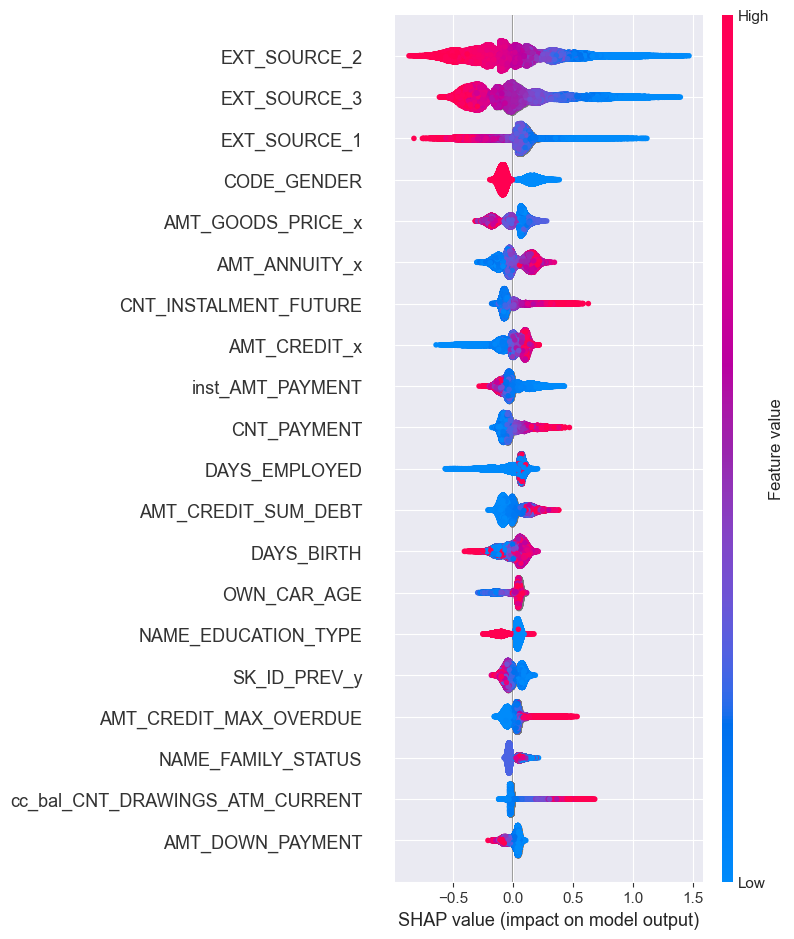

In [43]:
shap.summary_plot(shap_values, valid_X)

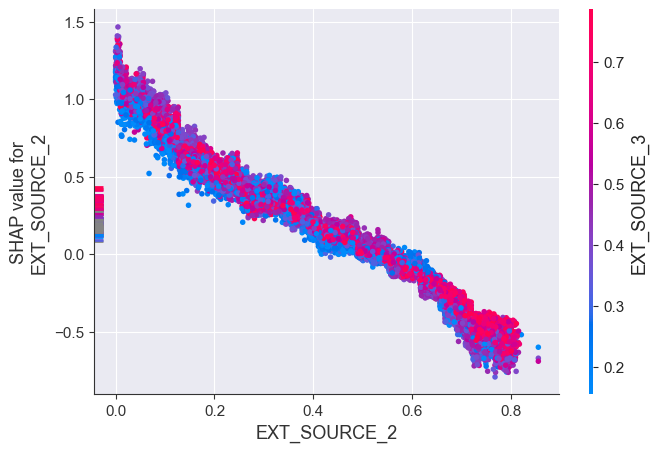

In [44]:
shap.dependence_plot("EXT_SOURCE_2", shap_values, valid_X)

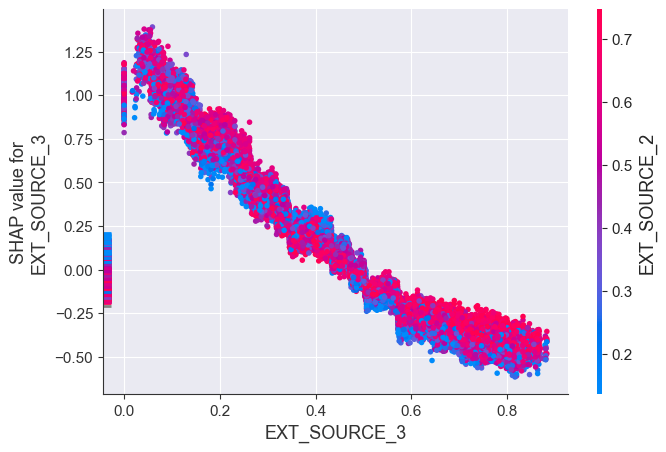

In [45]:
shap.dependence_plot("EXT_SOURCE_3", shap_values, valid_X)

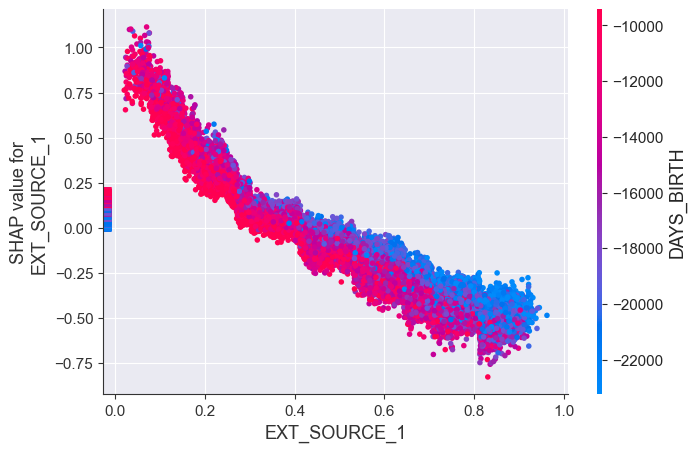

In [46]:
shap.dependence_plot("EXT_SOURCE_1", shap_values, valid_X)

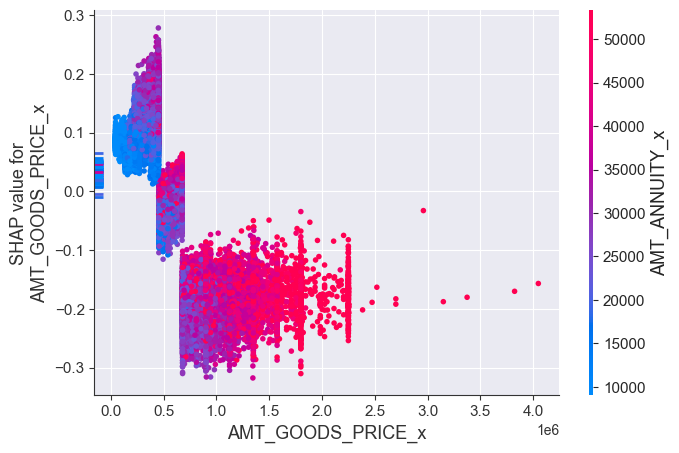

In [47]:
shap.dependence_plot("AMT_GOODS_PRICE_x", shap_values, valid_X)

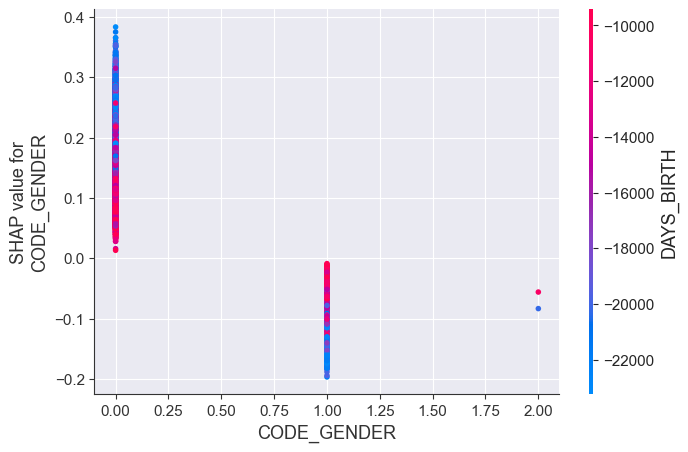

In [48]:
shap.dependence_plot("CODE_GENDER", shap_values, valid_X)

In [49]:
train_data['CODE_GENDER'].value_counts()

CODE_GENDER
1    202448
0    105059
2         4
Name: count, dtype: int64

In [50]:
train_data[train_data['CODE_GENDER'] == 2]

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT_x,AMT_ANNUITY_x,AMT_GOODS_PRICE_x,...,cc_bal_cc_bal_status__Refused,cc_bal_cc_bal_status__Sent_proposal,cc_bal_cc_bal_status__Signed,inst_SK_ID_PREV,inst_NUM_INSTALMENT_VERSION,inst_NUM_INSTALMENT_NUMBER,inst_DAYS_INSTALMENT,inst_DAYS_ENTRY_PAYMENT,inst_AMT_INSTALMENT,inst_AMT_PAYMENT
35657,141289,1,2,1,0,0,207000.0,382500.0,19125.0,337500.0,...,NaN,NaN,NaN,15.0,1.000000,4.400000,-762.000000,-778.466667,11790.282000,11790.282000
38566,144669,1,2,0,0,2,157500.0,270000.0,13500.0,225000.0,...,NaN,NaN,NaN,62.0,1.048387,7.193548,-1215.532258,-1224.903226,11347.951935,9678.811210
83382,196708,1,2,0,0,1,135000.0,405000.0,20250.0,225000.0,...,NaN,NaN,NaN,31.0,1.064516,3.516129,-1114.645161,-1136.645161,12515.642419,12068.880968
189640,319880,1,2,1,0,0,247500.0,540000.0,27000.0,900000.0,...,NaN,NaN,NaN,131.0,1.091603,6.938931,-881.816794,-900.610687,27793.835382,26409.696870


In [51]:
y[train_data['CODE_GENDER'] == 2].describe()

count    4.0
mean     0.0
std      0.0
min      0.0
25%      0.0
50%      0.0
75%      0.0
max      0.0
Name: TARGET, dtype: float64

In [52]:
test_data['CODE_GENDER'].value_counts()

CODE_GENDER
1    32678
0    16066
Name: count, dtype: int64

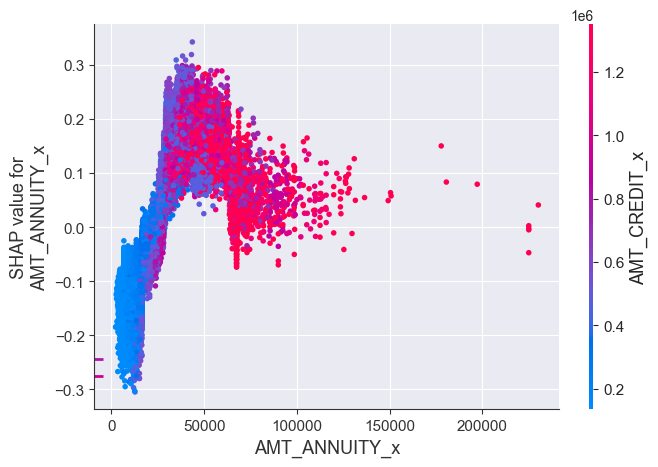

In [53]:
shap.dependence_plot("AMT_ANNUITY_x", shap_values, valid_X)

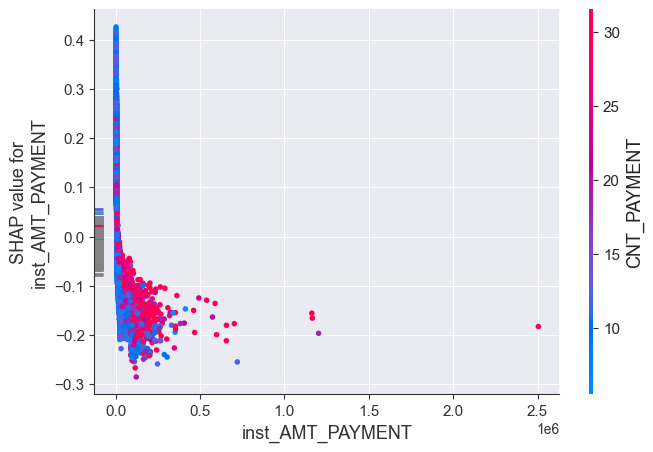

In [54]:
shap.dependence_plot("inst_AMT_PAYMENT", shap_values, valid_X)

In [55]:
y[train_data['inst_AMT_PAYMENT'] > 500000].describe()

count    62.000000
mean      0.048387
std       0.216335
min       0.000000
25%       0.000000
50%       0.000000
75%       0.000000
max       1.000000
Name: TARGET, dtype: float64

In [56]:
# Do those outliers also occur in the test set ?
test_data[test_data['inst_AMT_PAYMENT'] > 500000].filter(regex='EXT_SOURCE_.', axis=1).describe()

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
count,3.000000,13.000000,9.000000
mean,0.710731,0.559053,0.468030
std,0.280992,0.116202,0.179900
min,0.389453,0.350014,0.222581
25%,0.610778,0.514032,0.317032
50%,0.832103,0.545388,0.481249
75%,0.871370,0.651738,0.627991
max,0.910636,0.696409,0.728141


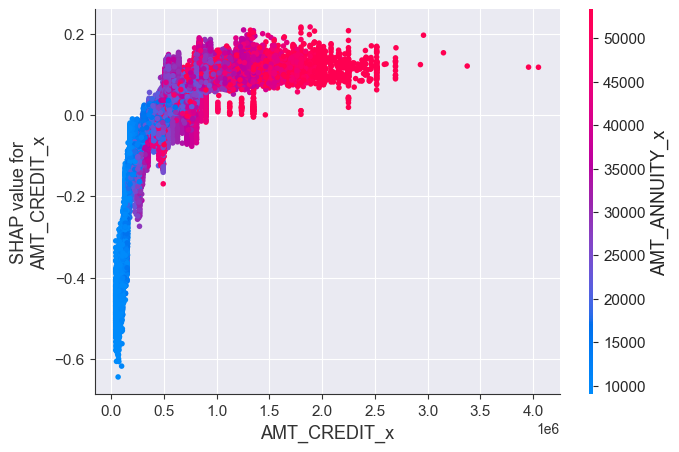

In [57]:
shap.dependence_plot("AMT_CREDIT_x", shap_values, valid_X)

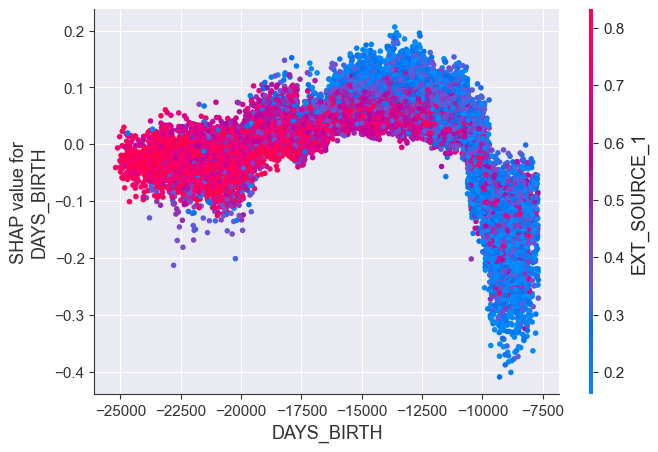

In [58]:
shap.dependence_plot("DAYS_BIRTH", shap_values, valid_X)

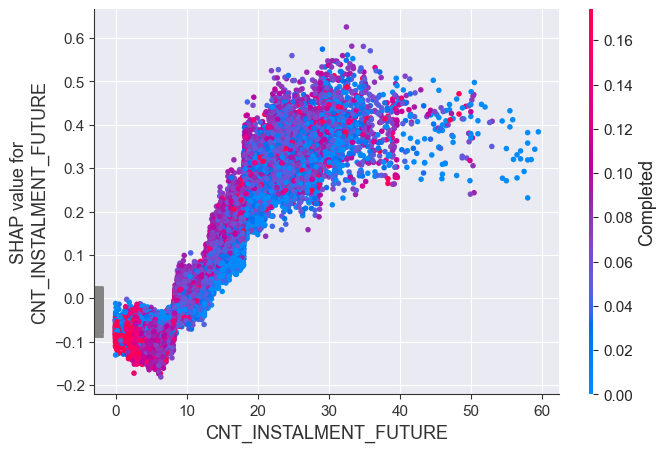

In [59]:
shap.dependence_plot("CNT_INSTALMENT_FUTURE", shap_values, valid_X)

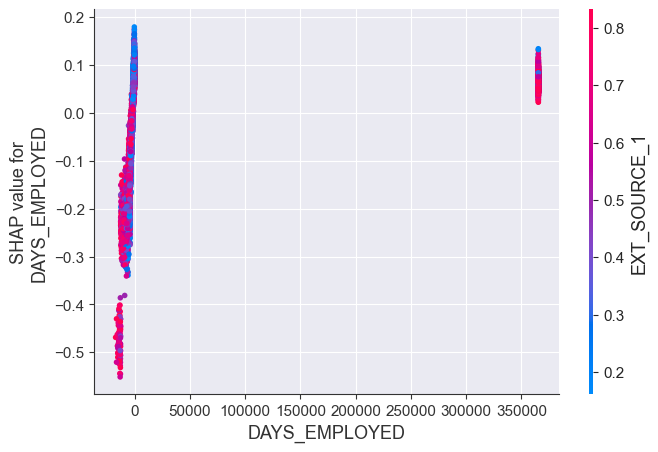

In [60]:
shap.dependence_plot("DAYS_EMPLOYED", shap_values, valid_X)

In [61]:
y[train_data['DAYS_EMPLOYED'] > 0].describe()

count    55374.000000
mean         0.053996
std          0.226013
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: TARGET, dtype: float64

<Axes: >

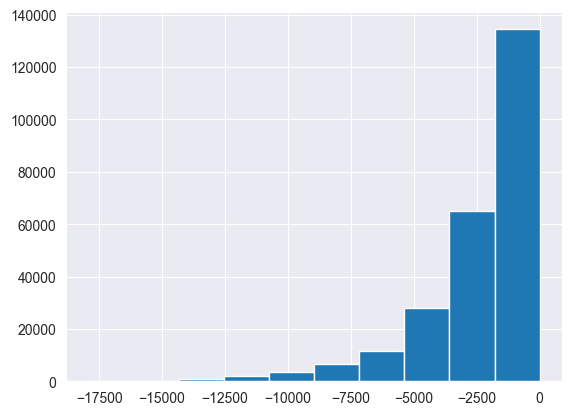

In [62]:
train_data[train_data['DAYS_EMPLOYED'] <= 0].DAYS_EMPLOYED.hist()

In [63]:
y[train_data['DAYS_EMPLOYED'] <= 0].describe()

count    252137.000000
mean          0.086600
std           0.281248
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: TARGET, dtype: float64

In [64]:
train_data[train_data['DAYS_EMPLOYED'] > 0].filter(regex='EXT_SOURCE_.', axis=1).describe()

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
count,12857.000000,55218.000000,44305.000000
mean,0.692897,0.506436,0.558835
std,0.161788,0.195964,0.181897
min,0.025084,0.000024,0.000527
25%,0.616968,0.363071,0.441836
50%,0.728865,0.560658,0.591977
75%,0.811266,0.662259,0.701696
max,0.962693,0.855000,0.896010


In [65]:
test_data[test_data['DAYS_EMPLOYED'] <= 0].filter(regex='EXT_SOURCE_.', axis=1).describe()

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
count,25033.000000,39463.000000,32355.000000
mean,0.483277,0.518170,0.490464
std,0.201288,0.180463,0.190352
min,0.013458,0.000008,0.000527
25%,0.328275,0.409349,0.352340
50%,0.485994,0.558750,0.506484
75%,0.641045,0.657948,0.644679
max,0.939145,0.855000,0.882530


In [66]:
# how many unemployed in the test set ?
test_data[test_data['DAYS_EMPLOYED'] > 0].filter(regex='EXT_SOURCE_.', axis=1).describe()

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
count,3179.000000,9273.000000,7721.000000
mean,0.642157,0.517385,0.540511
std,0.178968,0.184716,0.180369
min,0.017575,0.000402,0.000527
25%,0.531345,0.401545,0.420611
50%,0.677504,0.558766,0.565608
75%,0.781113,0.661241,0.681706
max,0.934145,0.855000,0.881027


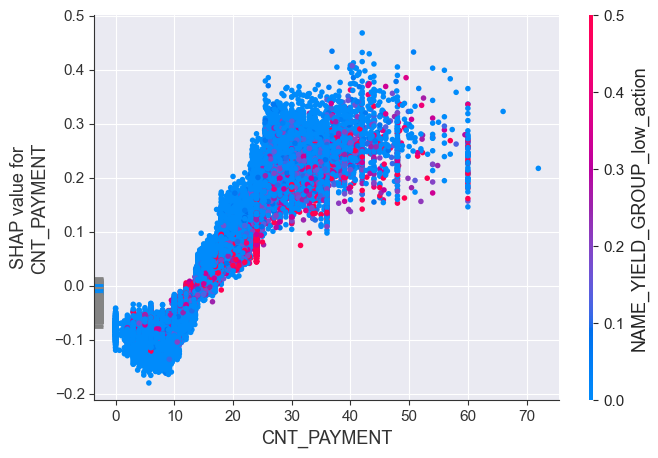

In [67]:
shap.dependence_plot("CNT_PAYMENT", shap_values, valid_X)

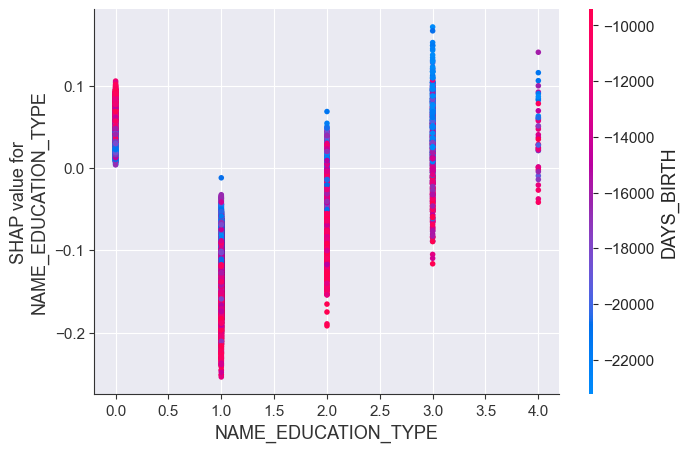

In [68]:
shap.dependence_plot("NAME_EDUCATION_TYPE", shap_values, valid_X)

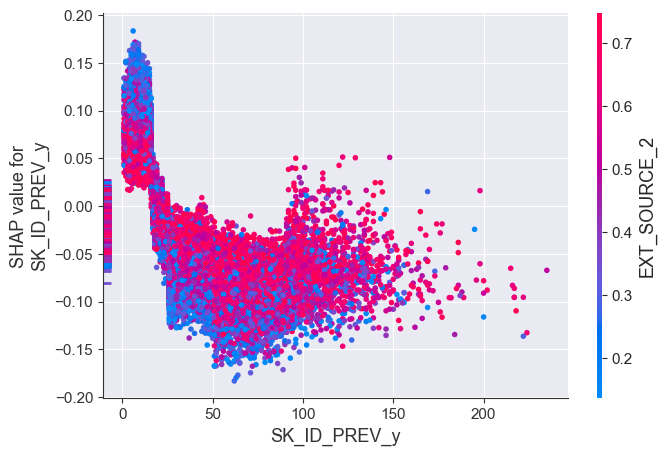

In [69]:
shap.dependence_plot("SK_ID_PREV_y", shap_values, valid_X)

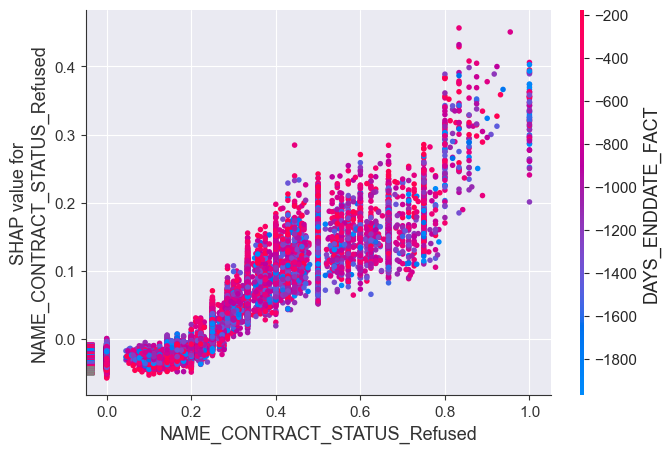

In [70]:
shap.dependence_plot("NAME_CONTRACT_STATUS_Refused", shap_values, valid_X)

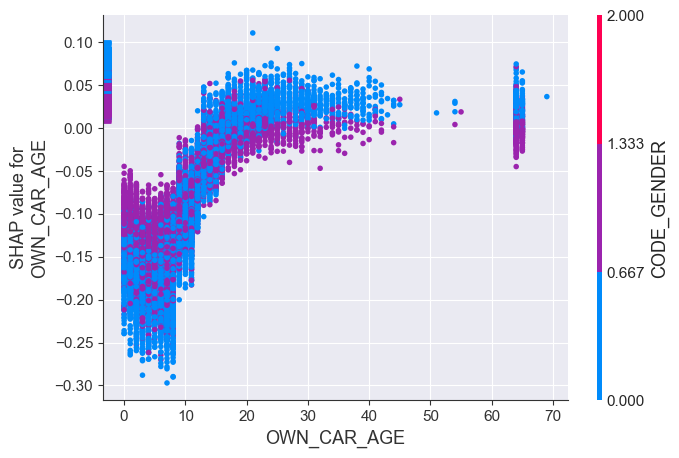

In [71]:
shap.dependence_plot("OWN_CAR_AGE", shap_values, valid_X)

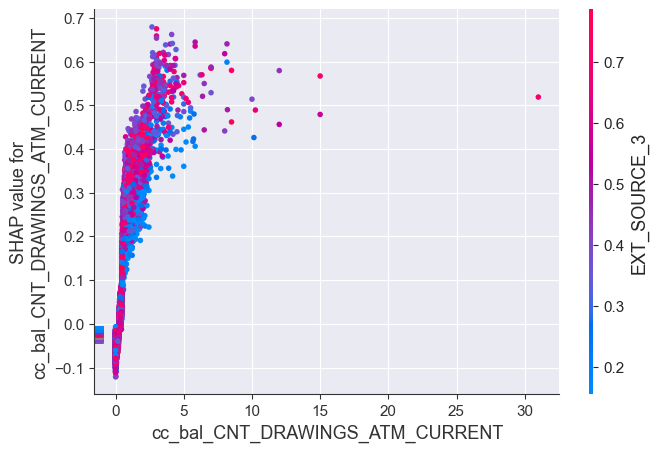

In [72]:
shap.dependence_plot("cc_bal_CNT_DRAWINGS_ATM_CURRENT", shap_values, valid_X)

In [73]:
y[train_data['cc_bal_CNT_DRAWINGS_ATM_CURRENT'] > 10].describe()

count    32.000000
mean      0.218750
std       0.420013
min       0.000000
25%       0.000000
50%       0.000000
75%       0.000000
max       1.000000
Name: TARGET, dtype: float64

In [74]:
test_data[test_data['cc_bal_CNT_DRAWINGS_ATM_CURRENT'] > 10].shape

(1, 380)

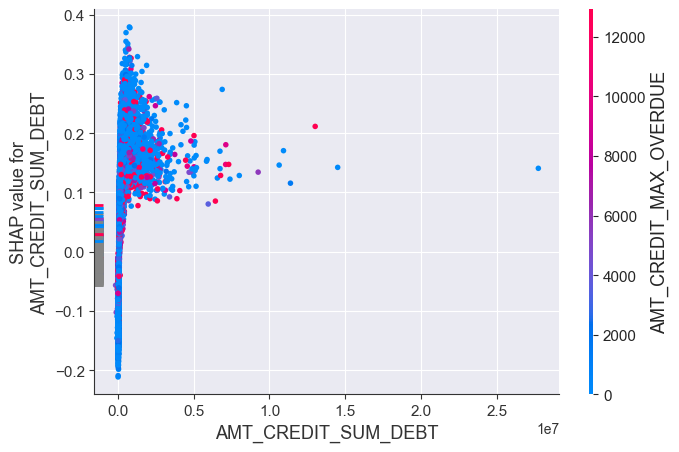

In [75]:
shap.dependence_plot("AMT_CREDIT_SUM_DEBT", shap_values, valid_X)

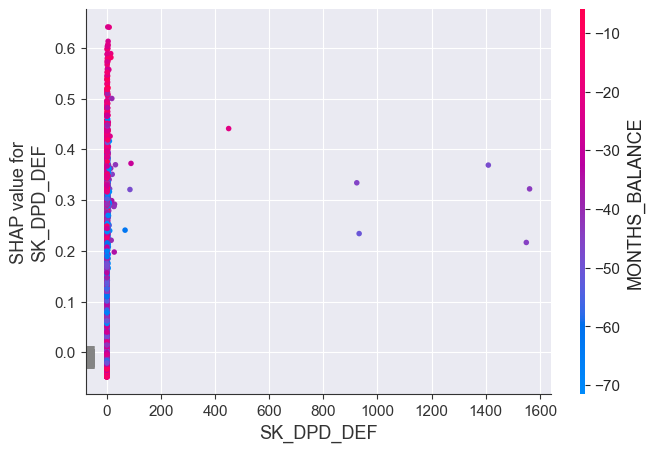

In [76]:
shap.dependence_plot("SK_DPD_DEF", shap_values, valid_X)

In [77]:
y[train_data['SK_DPD_DEF'] > 0].describe()

count    39890.000000
mean         0.107972
std          0.310349
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: TARGET, dtype: float64

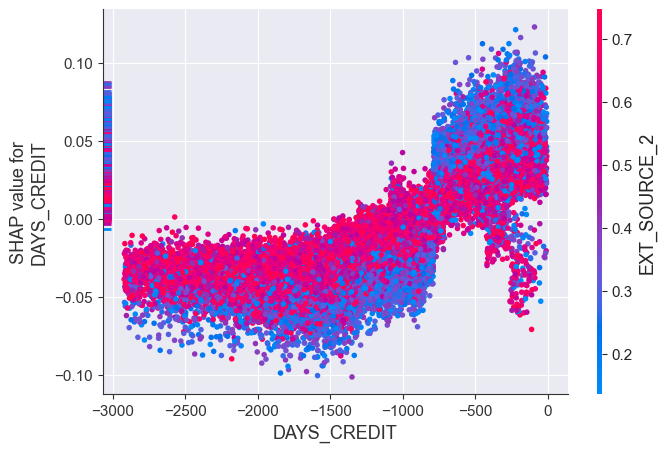

In [78]:
shap.dependence_plot("DAYS_CREDIT", shap_values, valid_X)